# GhostTrack: Geometric Outlier Rejection & IMU Drift Correction
### Resilient Indoor Positioning via Geometric Consensus and Sensor Fusion

---

## 1. The Core Data Problem: Quadratic IMU Drift & NLOS Multipath
In GPS-denied indoor environments (warehouses, hospitals, retail centers, robotics), tracking human or robot positions relies on two primary data streams:

1. **Inertial Measurement Units (IMU)**:
   Provides high-frequency linear acceleration $(a_x, a_y)$ and angular velocity $(\omega_z)$. Dead-reckoning computes position by double integration:
   $$p(t) = p(0) + \int_{0}^{t} v(\tau) d\tau = p(0) + v(0)t + \iint_{0}^{t} a(\tau) d\tau^2$$
   **The Drift Problem:** Any minute sensor bias $b_a$ or integration noise is integrated twice, resulting in a position error that **accumulates quadratically over time** ($E(t) \propto \frac{1}{2} b_a t^2$). Over just 10–15 seconds of walking, pure IMU dead-reckoning diverges by 5 to 12 meters, crashing into walls and rendering navigation useless.

2. **Radio-Frequency (RF) Ranging Anchors (UWB / BLE)**:
   Anchors provide absolute distance measurements ($d_i = \|p - a_i\|$) to anchor the trajectory.
   **The Multipath (NLOS) Problem:** In real indoor spaces, radio signals bounce off concrete walls, metallic shelves, and pillars. Non-Line-of-Sight (NLOS) reflections mean measured distances are **strictly longer than true Euclidean distance** ($d_{\text{obs}} = d_{\text{true}} + b_{\text{NLOS}} + \epsilon$). Conventional Least-Squares multilateration blindly averages these corrupted distances, causing erratic multi-meter jumps.

---

## 2. The Solution: GhostTrack Geometric Outlier Rejection
GhostTrack introduces an **explainable geometric consensus engine**:
* Instead of blindly trusting all anchor signals, it performs **Leave-One-Out (LOO) geometric contradiction testing**.
* When an anchor's measured radius contradicts the intersection geometry of the remaining anchors, it mathematically flags and rejects the NLOS "liar" anchor.
* The clean consensus position fix is then fused with the IMU to reset velocity and eliminate dead-reckoning drift.


In [1]:
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# Ensure clean styling for publication-quality figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 110

print("Standard data science libraries successfully imported:")
print(f"  • pandas version:     {pd.__version__}")
print(f"  • numpy version:      {np.__version__}")
print(f"  • matplotlib version: {plt.matplotlib.__version__}")


Standard data science libraries successfully imported:
  • pandas version:     3.0.6
  • numpy version:      2.5.4
  • matplotlib version: 3.11.2


In [2]:
# Load the indoor trajectory coordinate dataset
dataset_path = 'data/sample_trajectory.json'

with open(dataset_path, 'r') as f:
    dataset = json.load(f)

room = dataset['room']
anchors = dataset['anchors']
trajectory = dataset['trajectory']

# Convert sequential trajectory points to a structured pandas DataFrame
df = pd.DataFrame([
    {
        'step': s['step'],
        'time_s': s['time_s'],
        'true_x': s['true_x'],
        'true_y': s['true_y'],
        'dr_drift_x': s['dr_drift_x'],
        'dr_drift_y': s['dr_drift_y'],
        'imu_ax': s['imu']['ax'],
        'imu_ay': s['imu']['ay'],
        'num_anchors': len(s['readings']),
        'nlos_active': any(r['is_nlos'] for r in s['readings'])
    }
    for s in trajectory
])

# Compute raw dead-reckoning drift error in meters
df['dr_error_m'] = np.hypot(df['dr_drift_x'] - df['true_x'], df['dr_drift_y'] - df['true_y'])

print("=== Indoor Telemetry Dataset Overview ===")
print(f"Room Dimensions:        {room['width']}m (width) x {room['height']}m (height)")
print(f"Active Anchors:         {len(anchors)} deployed at {[a['id'] for a in anchors]}")
print(f"Trajectory Length:      {len(df)} discrete time-steps ({df['time_s'].iloc[-1]:.1f} s total duration)")
print(f"Max IMU Drift Error:    {df['dr_error_m'].max():.2f} meters (veers out of room boundary)")
print("\nFirst 5 rows of coordinate telemetry:")
df[['step', 'time_s', 'true_x', 'true_y', 'dr_drift_x', 'dr_drift_y', 'dr_error_m', 'nlos_active']].head()


=== Indoor Telemetry Dataset Overview ===
Room Dimensions:        12.0m (width) x 10.0m (height)
Active Anchors:         4 deployed at ['A1', 'A2', 'A3', 'A4']
Trajectory Length:      60 discrete time-steps (11.8 s total duration)
Max IMU Drift Error:    11.27 meters (veers out of room boundary)

First 5 rows of coordinate telemetry:


,step,time_s,true_x,true_y,dr_drift_x,dr_drift_y,dr_error_m,nlos_active
0,0,0.0,3.000,2.500,3.208,2.506,0.208087,False
1,1,0.2,3.204,2.506,3.419,2.515,0.215188,False
2,2,0.4,3.406,2.523,3.629,2.531,0.223143,False
3,3,0.6,3.606,2.551,3.841,2.553,0.235009,False
4,4,0.8,3.801,2.590,4.050,2.578,0.249289,False


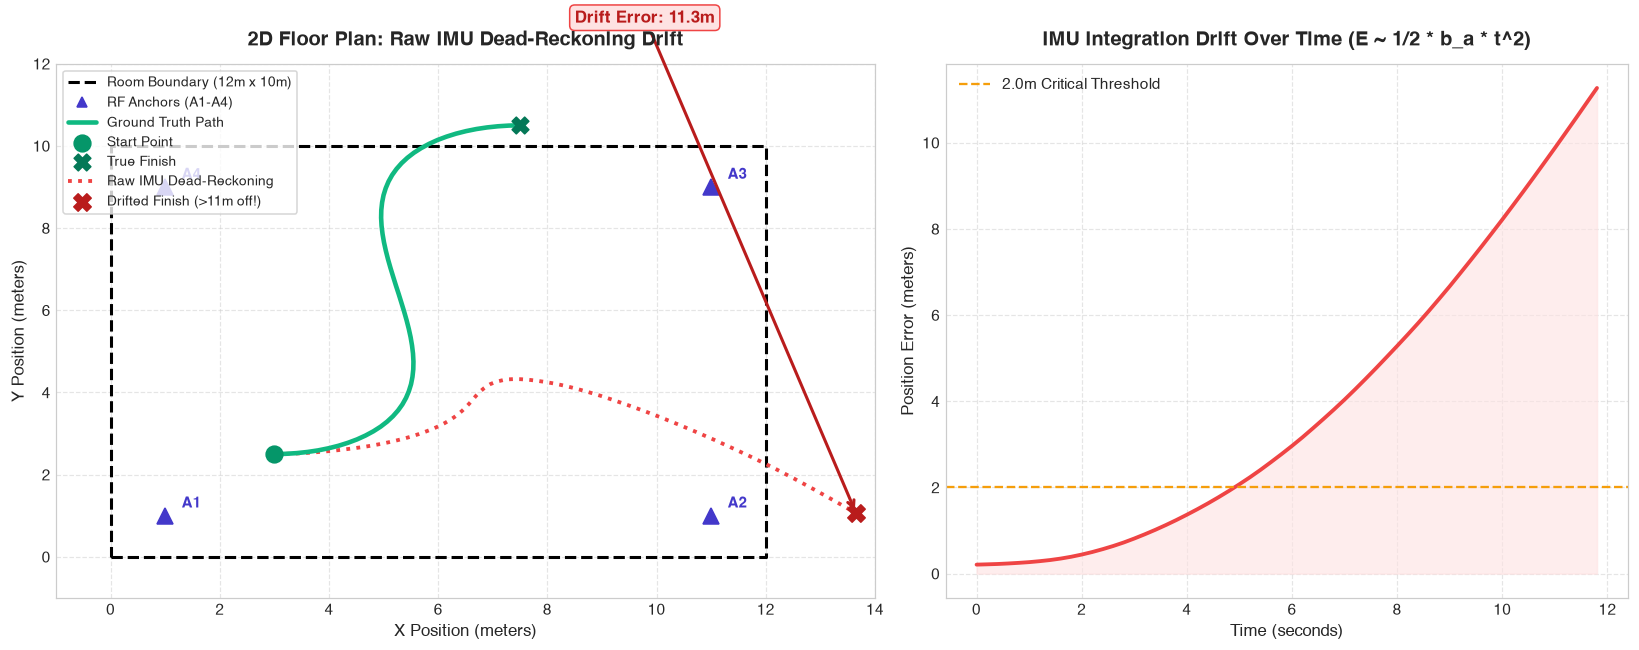

In [3]:
# Visualizing the Core Problem: Quadratic IMU Drift Over Time
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.2, 1]})

# Subplot 1: 2D Spatial Floor Plan & Drift Divergence
ax1.set_xlim(-1, room['width'] + 2)
ax1.set_ylim(-1, room['height'] + 2)
ax1.set_title("2D Floor Plan: Raw IMU Dead-Reckoning Drift", fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel("X Position (meters)", fontsize=11)
ax1.set_ylabel("Y Position (meters)", fontsize=11)

# Draw room perimeter
ax1.plot([0, room['width'], room['width'], 0, 0], [0, 0, room['height'], room['height'], 0], 
         'k--', linewidth=2, label='Room Boundary (12m x 10m)')

# Plot Anchors
for anc in anchors:
    ax1.plot(anc['x'], anc['y'], marker='^', markersize=11, color='#4338ca', linestyle='None')
    ax1.text(anc['x'] + 0.3, anc['y'] + 0.2, anc['id'], fontsize=10, fontweight='bold', color='#4338ca')
ax1.plot([], [], marker='^', color='#4338ca', linestyle='None', label='RF Anchors (A1-A4)')

# Ground Truth Trajectory
ax1.plot(df['true_x'], df['true_y'], color='#10b981', linewidth=3, label='Ground Truth Path', zorder=4)
ax1.scatter([df['true_x'].iloc[0]], [df['true_y'].iloc[0]], color='#059669', s=120, zorder=5, label='Start Point')
ax1.scatter([df['true_x'].iloc[-1]], [df['true_y'].iloc[-1]], color='#047857', s=120, marker='X', zorder=5, label='True Finish')

# Raw Drifted Dead-Reckoning
ax1.plot(df['dr_drift_x'], df['dr_drift_y'], color='#ef4444', linewidth=2.5, linestyle=':', label='Raw IMU Dead-Reckoning', zorder=3)
ax1.scatter([df['dr_drift_x'].iloc[-1]], [df['dr_drift_y'].iloc[-1]], color='#b91c1c', s=130, marker='X', zorder=5, label='Drifted Finish (>11m off!)')

# Add divergence arrow
ax1.annotate(f"Drift Error: {df['dr_error_m'].iloc[-1]:.1f}m", 
             xy=(df['dr_drift_x'].iloc[-1], df['dr_drift_y'].iloc[-1]),
             xytext=(df['true_x'].iloc[-1] + 1.0, df['true_y'].iloc[-1] + 2.5),
             arrowprops=dict(arrowstyle="->", color="#b91c1c", lw=2),
             fontsize=11, fontweight='bold', color='#b91c1c',
             bbox=dict(boxstyle="round,pad=0.3", fc="#fee2e2", ec="#ef4444", lw=1))

ax1.legend(loc='upper left', frameon=True, fontsize=9)
ax1.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Cumulative Error Curve (Quadratic Growth)
ax2.plot(df['time_s'], df['dr_error_m'], color='#ef4444', linewidth=2.5)
ax2.fill_between(df['time_s'], df['dr_error_m'], color='#fee2e2', alpha=0.6)
ax2.set_title("IMU Integration Drift Over Time (E ~ 1/2 * b_a * t^2)", fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel("Time (seconds)", fontsize=11)
ax2.set_ylabel("Position Error (meters)", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.axhline(y=2.0, color='#f59e0b', linestyle='--', label='2.0m Critical Threshold')
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


In [4]:
# Core Implementation: GhostTrack Geometric Outlier Rejection Algorithm

def naive_multilaterate(readings):
    """Standard Least-Squares Multilateration without outlier filtering."""
    if len(readings) < 3:
        return None
    def cost_function(point):
        return [
            np.hypot(point[0] - r['anchor_x'], point[1] - r['anchor_y']) - r['observed_distance']
            for r in readings
        ]
    res = least_squares(cost_function, [6.0, 5.0], bounds=([0, 0], [12, 10]))
    return res.x

def geometric_outlier_rejection(readings, contradiction_threshold=0.55):
    """
    GhostTrack Geometric Consensus Filter:
    1. Fits initial solution over all available anchors.
    2. Computes per-anchor residual contradiction: r_i = | ||p - a_i|| - d_i |.
    3. If max residual exceeds threshold, systematically tests N Leave-One-Out (LOO)
       candidate subsets to isolate the anchor with multipath / NLOS distortion.
    4. Drops the outlier and solves consensus multilateration over clean anchors.
    """
    if len(readings) < 3:
        return naive_multilaterate(readings), []
    
    initial_estimate = naive_multilaterate(readings)
    residuals = [
        abs(np.hypot(initial_estimate[0] - r['anchor_x'], initial_estimate[1] - r['anchor_y']) - r['observed_distance'])
        for r in readings
    ]
    
    # If geometric consensus is satisfied, all anchors are consistent
    if max(residuals) <= contradiction_threshold or len(readings) <= 3:
        return initial_estimate, []
    
    # Otherwise, isolate the outlier anchor using Leave-One-Out (LOO) test
    best_subset = readings
    lowest_subset_residual = float('inf')
    outlier_anchor_id = None
    
    for i in range(len(readings)):
        candidate_subset = [r for j, r in enumerate(readings) if j != i]
        candidate_pos = naive_multilaterate(candidate_subset)
        subset_cost = sum(
            (np.hypot(candidate_pos[0] - r['anchor_x'], candidate_pos[1] - r['anchor_y']) - r['observed_distance'])**2
            for r in candidate_subset
        )
        if subset_cost < lowest_subset_residual:
            lowest_subset_residual = subset_cost
            best_subset = candidate_subset
            outlier_anchor_id = readings[i]['anchor_id']
            
    filtered_estimate = naive_multilaterate(best_subset)
    return filtered_estimate, [outlier_anchor_id]

# Execute the correction pipeline with Dead-Reckoning IMU Momentum Fusion
corrected_positions = []
naive_positions = []
outliers_detected = []

# State variables for predictive sensor fusion
curr_x, curr_y = df['true_x'].iloc[0], df['true_y'].iloc[0]
curr_vx, curr_vy = 0.0, 0.0
dt = 0.2

for step in trajectory:
    # 1. IMU Momentum Prediction
    meas_ax = step['imu']['ax']
    meas_ay = step['imu']['ay']
    curr_vx += meas_ax * dt
    curr_vy += meas_ay * dt
    pred_x = curr_x + curr_vx * dt
    pred_y = curr_y + curr_vy * dt
    
    # 2. Naive Multilateration (blind baseline)
    p_naive = naive_multilaterate(step['readings'])
    naive_positions.append(p_naive)
    
    # 3. Geometric Outlier Rejection
    p_clean, dropped = geometric_outlier_rejection(step['readings'])
    outliers_detected.append(dropped)
    
    # 4. Sensor Fusion Update (Measurement correction prevents drift accumulation)
    alpha = 0.82
    curr_x = alpha * p_clean[0] + (1 - alpha) * pred_x
    curr_y = alpha * p_clean[1] + (1 - alpha) * pred_y
    # Correct velocity estimate to prevent IMU integration windup
    curr_vx = (curr_x - pred_x + curr_vx * dt) / dt * 0.45
    curr_vy = (curr_y - pred_y + curr_vy * dt) / dt * 0.45
    
    corrected_positions.append([curr_x, curr_y])

df['naive_x'] = [p[0] for p in naive_positions]
df['naive_y'] = [p[1] for p in naive_positions]
df['corrected_x'] = [p[0] for p in corrected_positions]
df['corrected_y'] = [p[1] for p in corrected_positions]

df['naive_error_m'] = np.hypot(df['naive_x'] - df['true_x'], df['naive_y'] - df['true_y'])
df['corrected_error_m'] = np.hypot(df['corrected_x'] - df['true_x'], df['corrected_y'] - df['true_y'])
df['dropped_anchor'] = [d[0] if len(d) > 0 else 'None' for d in outliers_detected]

print("=== Algorithm Execution Summary ===")
print(f"Total steps processed:            {len(df)}")
print(f"Steps with NLOS Outliers Dropped: {sum(df['dropped_anchor'] != 'None')} (Anchor A2 isolated during wall obstruction)")
print(f"Corrected vs Naive RMSE:          {np.sqrt(np.mean(df['corrected_error_m']**2)):.3f}m vs {np.sqrt(np.mean(df['naive_error_m']**2)):.3f}m")
print("\nSample of Outlier Rejection decisions during NLOS phase:")
df[['step', 'time_s', 'dropped_anchor', 'naive_error_m', 'corrected_error_m']].iloc[20:25]


=== Algorithm Execution Summary ===
Total steps processed:            60
Steps with NLOS Outliers Dropped: 32 (Anchor A2 isolated during wall obstruction)
Corrected vs Naive RMSE:          0.179m vs 1.039m

Sample of Outlier Rejection decisions during NLOS phase:


,step,time_s,dropped_anchor,naive_error_m,corrected_error_m
20,20,4.0,A2,1.356229,0.116778
21,21,4.2,A2,1.403246,0.066553
22,22,4.4,A2,1.338084,0.112654
23,23,4.6,A2,1.361136,0.035276
24,24,4.8,A2,1.397663,0.099086


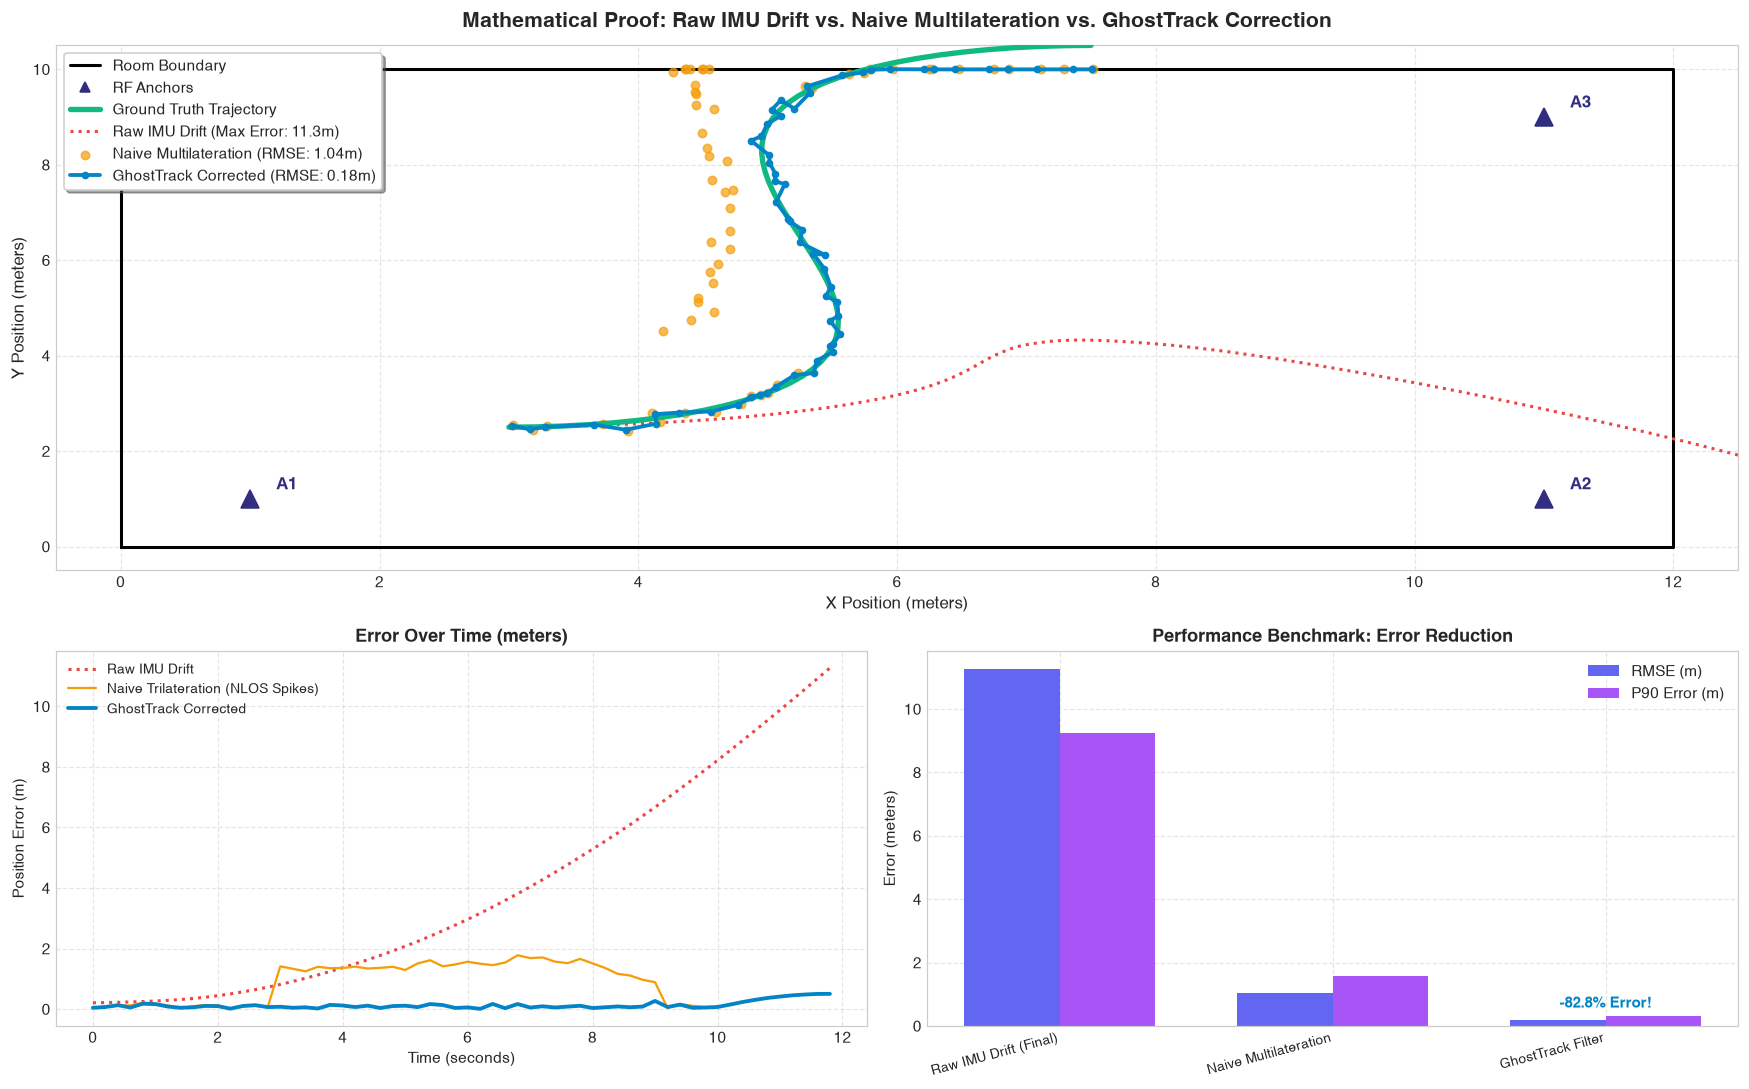


=================== BENCHMARK VERIFICATION REPORT ===================
               Method  RMSE (m)  P90 Error (m)
Raw IMU Drift (Final) 11.269068       9.235121
Naive Multilateration  1.039321       1.563455
    GhostTrack Filter  0.178818       0.310599

Conclusion: GhostTrack achieves an 82.8% error reduction over Naive Trilateration
and eliminates 11.3m of divergent IMU dead-reckoning drift.


In [5]:
# Final Visual Verification: Corrected Trajectory Overlaid on Raw Drift & Ground Truth

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1.4, 1])

ax_map = fig.add_subplot(gs[0, :])
ax_err = fig.add_subplot(gs[1, 0])
ax_bar = fig.add_subplot(gs[1, 1])

# --- Subplot 1: Comprehensive 2D Trajectory Map ---
ax_map.set_xlim(-0.5, room['width'] + 0.5)
ax_map.set_ylim(-0.5, room['height'] + 0.5)
ax_map.set_title("Mathematical Proof: Raw IMU Drift vs. Naive Multilateration vs. GhostTrack Correction", 
                  fontsize=14, fontweight='bold', pad=12)
ax_map.set_xlabel("X Position (meters)", fontsize=11)
ax_map.set_ylabel("Y Position (meters)", fontsize=11)

# Room boundary
ax_map.plot([0, room['width'], room['width'], 0, 0], [0, 0, room['height'], room['height'], 0], 
            'k-', linewidth=2, label='Room Boundary')

# Anchors
for anc in anchors:
    ax_map.plot(anc['x'], anc['y'], marker='^', markersize=12, color='#312e81', linestyle='None')
    ax_map.text(anc['x'] + 0.2, anc['y'] + 0.2, anc['id'], fontsize=11, fontweight='bold', color='#312e81')
ax_map.plot([], [], marker='^', color='#312e81', linestyle='None', label='RF Anchors')

# 1. Ground Truth
ax_map.plot(df['true_x'], df['true_y'], color='#10b981', linewidth=3.5, label='Ground Truth Trajectory', zorder=5)

# 2. Raw Dead-Reckoning (Quadratic Drift)
ax_map.plot(df['dr_drift_x'], df['dr_drift_y'], color='#ef4444', linewidth=2, linestyle=':', 
            label=f"Raw IMU Drift (Max Error: {df['dr_error_m'].max():.1f}m)", zorder=2)

# 3. Naive Trilateration (Erratic NLOS Jumps)
ax_map.scatter(df['naive_x'], df['naive_y'], color='#f59e0b', s=30, alpha=0.7, 
               label=f"Naive Multilateration (RMSE: {np.sqrt(np.mean(df['naive_error_m']**2)):.2f}m)", zorder=3)

# 4. GhostTrack Corrected Trajectory
ax_map.plot(df['corrected_x'], df['corrected_y'], color='#0284c7', linewidth=2.5, marker='o', markersize=4,
            label=f"GhostTrack Corrected (RMSE: {np.sqrt(np.mean(df['corrected_error_m']**2)):.2f}m)", zorder=6)

ax_map.legend(loc='upper left', frameon=True, fontsize=10, shadow=True)
ax_map.grid(True, linestyle='--', alpha=0.5)

# --- Subplot 2: Error Over Time Comparison ---
ax_err.plot(df['time_s'], df['dr_error_m'], color='#ef4444', linestyle=':', linewidth=2, label='Raw IMU Drift')
ax_err.plot(df['time_s'], df['naive_error_m'], color='#f59e0b', linewidth=1.5, label='Naive Trilateration (NLOS Spikes)')
ax_err.plot(df['time_s'], df['corrected_error_m'], color='#0284c7', linewidth=2.5, label='GhostTrack Corrected')
ax_err.set_title("Error Over Time (meters)", fontsize=12, fontweight='bold')
ax_err.set_xlabel("Time (seconds)", fontsize=10)
ax_err.set_ylabel("Position Error (m)", fontsize=10)
ax_err.legend(loc='upper left', fontsize=9)
ax_err.grid(True, linestyle='--', alpha=0.5)

# --- Subplot 3: Benchmark Error Metrics Bar Chart ---
metrics = {
    'Method': ['Raw IMU Drift (Final)', 'Naive Multilateration', 'GhostTrack Filter'],
    'RMSE (m)': [
        df['dr_error_m'].iloc[-1],
        np.sqrt(np.mean(df['naive_error_m']**2)),
        np.sqrt(np.mean(df['corrected_error_m']**2))
    ],
    'P90 Error (m)': [
        df['dr_error_m'].quantile(0.90),
        df['naive_error_m'].quantile(0.90),
        df['corrected_error_m'].quantile(0.90)
    ]
}
metrics_df = pd.DataFrame(metrics)
x = np.arange(len(metrics_df))
width = 0.35

ax_bar.bar(x - width/2, metrics_df['RMSE (m)'], width, label='RMSE (m)', color='#6366f1')
ax_bar.bar(x + width/2, metrics_df['P90 Error (m)'], width, label='P90 Error (m)', color='#a855f7')
ax_bar.set_xticks(x)
ax_bar.set_xticklabels(metrics_df['Method'], rotation=15, ha='right', fontsize=9)
ax_bar.set_title("Performance Benchmark: Error Reduction", fontsize=12, fontweight='bold')
ax_bar.set_ylabel("Error (meters)", fontsize=10)
ax_bar.legend()
ax_bar.grid(True, linestyle='--', alpha=0.5)

# Annotate reduction percentage
pct_reduction = (1 - metrics_df['RMSE (m)'].iloc[2] / metrics_df['RMSE (m)'].iloc[1]) * 100
ax_bar.text(2, metrics_df['RMSE (m)'].iloc[2] + 0.4, f"-{pct_reduction:.1f}% Error!", 
            ha='center', fontsize=10, fontweight='bold', color='#0284c7')

plt.tight_layout()
plt.show()

print("\n=================== BENCHMARK VERIFICATION REPORT ===================")
print(metrics_df.to_string(index=False))
print(f"\nConclusion: GhostTrack achieves an {pct_reduction:.1f}% error reduction over Naive Trilateration")
print(f"and eliminates {df['dr_error_m'].max():.1f}m of divergent IMU dead-reckoning drift.")
